# WildfireSpreadTS (WSTS) — Exploratory Data Analysis

## Project
FireGuard: Next-Day Wildfire Spread Prediction

## Role
Role 1 — WSTS / Geospatial Data Engineer

## Objective
This notebook performs a reproducible exploratory inspection of the WildfireSpreadTS dataset.

The analysis covers:

1. Dataset inventory and organization.
2. GeoTIFF metadata and spatial properties.
3. Original 23-band feature inspection.
4. Processed 40-channel loader inspection.
5. Active-fire target distribution.
6. Data quality and missing-value analysis.

## Dataset provenance
- Dataset: WildfireSpreadTS
- Zenodo: https://zenodo.org/records/8006177
- Baseline repository: https://github.com/SebastianGer/WildfireSpreadTS
- Pinned baseline commit: `f62dc49f2c2a6d249c071533ae5340c0d01bfb95`

## Data location
The extracted dataset is stored in Google Drive. Raw dataset files are not committed to GitHub.

## Important note
This notebook is intended for Phase 1 dataset inspection. It does not implement model training, data splitting, or Phase 2 preprocessing.

In [1]:
from pathlib import Path

notebook_dir = Path("/content/fireguard/notebooks")
notebook_dir.mkdir(parents=True, exist_ok=True)

print("Notebook directory:", notebook_dir)
print("Directory exists:", notebook_dir.exists())

Notebook directory: /content/fireguard/notebooks
Directory exists: True


In [3]:
# ==========================================
# 1. ENVIRONMENT AND DATASET CONFIGURATION
# ==========================================

from pathlib import Path
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from google.colab import drive

warnings.filterwarnings("ignore")

# Mount Google Drive
drive.mount("/content/drive")

# Project paths
PROJECT_ROOT = Path("/content/fireguard")

DATA_ROOT = Path(
    "/content/drive/MyDrive/FireGuard/data/extracted"
)

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/FireGuard/data/manifests/wsts_event_metadata.csv"
)

# Check paths
print("Project root exists:", PROJECT_ROOT.exists())
print("Dataset root exists:", DATA_ROOT.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

assert DATA_ROOT.exists(), "Dataset directory not found."
assert MANIFEST_PATH.exists(), "Event metadata manifest not found."

# Load event metadata
event_metadata = pd.read_csv(MANIFEST_PATH)

print("\nEvent metadata shape:", event_metadata.shape)
print("\nEvents by year:")
display(event_metadata["year"].value_counts().sort_index())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root exists: True
Dataset root exists: True
Manifest exists: True

Event metadata shape: (607, 24)

Events by year:


,count
year,
2018,176
2019,74
2020,201
2021,156


In [4]:
# ==========================================
# 2. DATASET INVENTORY
# ==========================================

year_summary = []

for year in sorted(event_metadata["year"].unique()):

    year_path = DATA_ROOT / str(year)

    # Find event directories
    event_dirs = sorted([
        p for p in year_path.iterdir()
        if p.is_dir()
    ])

    # Count TIFF files
    tiff_count = sum(
        len(list(event_dir.glob("*.tif")))
        for event_dir in event_dirs
    )

    year_summary.append({
        "year": int(year),
        "event_count": len(event_dirs),
        "tiff_count": tiff_count
    })

year_summary_df = pd.DataFrame(year_summary)

print("WSTS DATASET INVENTORY")
display(year_summary_df)

print("\nTotal events:", year_summary_df["event_count"].sum())
print("Total TIFF files:", year_summary_df["tiff_count"].sum())

# Compare directory counts with manifest
manifest_counts = (
    event_metadata.groupby("year")
    .size()
    .rename("manifest_event_count")
)

comparison = (
    year_summary_df.set_index("year")
    .join(manifest_counts)
)

comparison["counts_match"] = (
    comparison["event_count"] ==
    comparison["manifest_event_count"]
)

print("\nManifest vs actual directory comparison:")
display(comparison)

WSTS DATASET INVENTORY


,year,event_count,tiff_count
0,2018,176,3773
1,2019,74,1425
2,2020,201,4292
3,2021,156,4117



Total events: 607
Total TIFF files: 13607

Manifest vs actual directory comparison:


,event_count,tiff_count,manifest_event_count,counts_match
year,,,,
2018,176,3773,176,True
2019,74,1425,74,True
2020,201,4292,201,True
2021,156,4117,156,True


In [5]:
# ==========================================
# 3. FILE COUNT RECONCILIATION
# ==========================================

from collections import Counter

extension_counts = Counter()
total_files = 0

for path in DATA_ROOT.rglob("*"):
    if path.is_file():
        total_files += 1
        extension = path.suffix.lower() or "[no extension]"
        extension_counts[extension] += 1

print("Total files under extracted dataset:", total_files)
print("\nFiles by extension:")

for extension, count in sorted(extension_counts.items()):
    print(f"{extension}: {count}")

print("\nTIFF files from directory scan:",
      extension_counts[".tif"])

print("\nPreviously recorded extracted files: 14,218")
print("Current total files:", total_files)
print("Difference:", 14218 - total_files)

Total files under extracted dataset: 13607

Files by extension:
.tif: 13607

TIFF files from directory scan: 13607

Previously recorded extracted files: 14,218
Current total files: 13607
Difference: 611


In [6]:
# ==========================================
# 4. EVENT-LEVEL TIFF COUNT VALIDATION
# ==========================================

manifest = pd.read_csv(MANIFEST_PATH)

actual_counts = []

for _, row in manifest.iterrows():

    year = int(row["year"])
    event_id = row["event_id"]

    event_path = DATA_ROOT / str(year) / event_id

    actual_tiffs = (
        len(list(event_path.glob("*.tif")))
        if event_path.exists()
        else 0
    )

    actual_counts.append({
        "year": year,
        "event_id": event_id,
        "manifest_tiff_count": row["tiff_count"],
        "actual_tiff_count": actual_tiffs,
        "directory_exists": event_path.exists()
    })

event_check = pd.DataFrame(actual_counts)

print("Events checked:", len(event_check))
print("Missing directories:",
      (~event_check["directory_exists"]).sum())

print("Events with count mismatch:",
      (event_check["manifest_tiff_count"] !=
       event_check["actual_tiff_count"]).sum())

display(
    event_check[
        event_check["manifest_tiff_count"] !=
        event_check["actual_tiff_count"]
    ].head(20)
)

Events checked: 607
Missing directories: 0
Events with count mismatch: 0


,year,event_id,manifest_tiff_count,actual_tiff_count,directory_exists


In [7]:
# ==========================================
# 5. GEOTIFF METADATA INSPECTION
# ==========================================

SAMPLE_EVENT = "fire_21458798"
SAMPLE_YEAR = 2018

sample_event_dir = DATA_ROOT / str(SAMPLE_YEAR) / SAMPLE_EVENT

tiff_files = sorted(sample_event_dir.glob("*.tif"))

print("Event:", SAMPLE_EVENT)
print("Number of TIFF files:", len(tiff_files))
print("First TIFF:", tiff_files[0].name)
print("Last TIFF:", tiff_files[-1].name)

# Inspect January 6, 2018
sample_tiff = sample_event_dir / "2018-01-06.tif"

with rasterio.open(sample_tiff) as src:

    print("\n--- Raster metadata ---")
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data types:", src.dtypes)
    print("Nodata:", src.nodata)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)

    raster = src.read()

print("\nArray shape:", raster.shape)
print("Array dtype:", raster.dtype)

Event: fire_21458798
Number of TIFF files: 14
First TIFF: 2018-01-01.tif
Last TIFF: 2018-01-14.tif

--- Raster metadata ---
Width: 247
Height: 304
Band count: 23
CRS: EPSG:32610
Resolution: (375.0, 375.0)
Data types: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
Nodata: None
Bounds: BoundingBox(left=697500.0, bottom=4022625.0, right=790125.0, top=4136625.0)
Transform: | 375.00, 0.00, 697500.00|
| 0.00,-375.00, 4136625.00|
| 0.00, 0.00, 1.00|

Array shape: (23, 304, 247)
Array dtype: float32


### **Sample GeoTIFF Metadata Inspection**
## Sample GeoTIFF Metadata Inspection

Sample event: `fire_21458798` (2018)

- Number of daily TIFF files: 14
- Date range: 2018-01-01 to 2018-01-14
- Raster width: 247 columns
- Raster height: 304 rows
- Number of bands: 23
- Array layout: (bands, rows, columns)
- CRS: EPSG:32610
- Pixel resolution: 375 m × 375 m
- Data type: float32
- Dataset-level nodata metadata: None

The inspected raster has 23 float32 bands and a projected
375 m spatial grid. The absence of a dataset-level nodata
value does not imply that all individual band pixels are valid.

In [8]:
# 6. PER-BAND DATA QUALITY INSPECTION

import numpy as np
import pandas as pd
import rasterio

sample_tiff = (
    DATA_ROOT / "2018" / "fire_21458798" / "2018-01-06.tif"
)

with rasterio.open(sample_tiff) as src:
    raster = src.read()

band_quality = []

for band_idx in range(raster.shape[0]):
    band = raster[band_idx]

    finite_values = band[np.isfinite(band)]

    band_quality.append({
        "band_index": band_idx,
        "total_pixels": band.size,
        "nan_count": int(np.isnan(band).sum()),
        "positive_inf_count": int(np.isposinf(band).sum()),
        "negative_inf_count": int(np.isneginf(band).sum()),
        "finite_count": int(np.isfinite(band).sum()),
        "finite_min": (
            float(finite_values.min())
            if finite_values.size else np.nan
        ),
        "finite_max": (
            float(finite_values.max())
            if finite_values.size else np.nan
        ),
        "finite_mean": (
            float(finite_values.mean())
            if finite_values.size else np.nan
        )
    })

band_quality_df = pd.DataFrame(band_quality)

display(band_quality_df)

,band_index,total_pixels,nan_count,positive_inf_count,negative_inf_count,finite_count,finite_min,finite_max,finite_mean
0,0,75088,0,0,0,75088,857.000000,6694.000000,3984.554443
1,1,75088,0,0,0,75088,672.000000,13084.000000,6198.055176
2,2,75088,0,0,0,75088,-100.000000,12240.000000,6014.635254
3,3,75088,0,0,0,75088,-5354.000000,9246.000000,3342.108398
4,4,75088,0,0,0,75088,-1212.000000,9577.000000,1791.945435
5,5,75088,0,0,0,75088,0.000000,11.000000,1.377967
6,6,75088,0,0,0,75088,1.200000,2.400000,2.050342
7,7,75088,0,0,0,75088,156.000000,342.000000,300.261932
8,8,75088,0,0,0,75088,278.500000,287.100006,282.168182
9,9,75088,0,0,0,75088,284.000000,290.799988,288.642761


## Per-band Data Quality Inspection

Inspected file: `2018/ fire_21458798 / 2018-01-06.tif`

The raster contains 23 bands and 75,088 pixels per band.

- Bands 0–21: all 75,088 pixels are finite.
- Band 22 (Active fire): all 75,088 pixels are NaN.
- Positive and negative infinity values: none in any band.

The active-fire input band is entirely missing in this particular
daily raster. The baseline loader replaces NaNs in the active-fire
input channel with zero.

This finding is specific to the inspected date and must not be
generalized to all events or dates. Physical units and scale factors
for the other channels require verification against their source
products and preprocessing code.

In [9]:
# 7. ACTIVE-FIRE BAND MISSINGNESS ACROSS THE EVENT

import numpy as np
import pandas as pd
import rasterio

event_dir = DATA_ROOT / "2018" / "fire_21458798"
tiff_files = sorted(event_dir.glob("*.tif"))

active_fire_quality = []

for tiff_path in tiff_files:
    with rasterio.open(tiff_path) as src:
        active_fire = src.read(23)

    total = active_fire.size
    finite_count = int(np.isfinite(active_fire).sum())
    nan_count = int(np.isnan(active_fire).sum())

    finite_values = active_fire[np.isfinite(active_fire)]

    active_fire_quality.append({
        "date": tiff_path.stem,
        "total_pixels": total,
        "finite_count": finite_count,
        "nan_count": nan_count,
        "finite_min": (
            float(finite_values.min())
            if finite_values.size else np.nan
        ),
        "finite_max": (
            float(finite_values.max())
            if finite_values.size else np.nan
        ),
        "positive_pixel_count": int(
            np.sum(finite_values > 0)
        )
    })

active_fire_quality_df = pd.DataFrame(active_fire_quality)

display(active_fire_quality_df)

,date,total_pixels,finite_count,nan_count,finite_min,finite_max,positive_pixel_count
0,2018-01-01,75088,4,75084,854.0,854.0,4
1,2018-01-02,75088,0,75088,NaN,NaN,0
2,2018-01-03,75088,0,75088,NaN,NaN,0
3,2018-01-04,75088,0,75088,NaN,NaN,0
4,2018-01-05,75088,0,75088,NaN,NaN,0
5,2018-01-06,75088,0,75088,NaN,NaN,0
6,2018-01-07,75088,10,75078,2006.0,2006.0,10
7,2018-01-08,75088,0,75088,NaN,NaN,0
8,2018-01-09,75088,0,75088,NaN,NaN,0
9,2018-01-10,75088,4,75084,2048.0,2048.0,4


## Active-fire Band Missingness Across the Event

Event: `fire_21458798` (2018-01-01 to 2018-01-14)

Band 22 (Active fire) was inspected across all 14 daily GeoTIFFs.

- Dates with finite active-fire pixels: 4
- Dates with an entirely NaN active-fire band: 10
- Total positive pixels across the 14 dates: 78

Finite active-fire values occurred on:
- 2018-01-01: 4 pixels, value 854
- 2018-01-07: 10 pixels, value 2006
- 2018-01-10: 4 pixels, value 2048
- 2018-01-11: 34 pixels, range 912–2030
- 2018-01-12: 26 pixels, range 848–2012

Correction: the dates with finite values are January 1, 7, 10, 11, and 12.
There are therefore 5 dates with finite values and 9 dates with
an entirely NaN active-fire band.

The baseline loader replaces NaNs in the active-fire input channel
with zero. This should not be interpreted as proof that the original
observation confirmed an absence of fire.

In [10]:
# 8. RAW ACTIVE-FIRE VS LOADER TARGET ALIGNMENT

import numpy as np
import rasterio
import torch

raw_target_path = (
    DATA_ROOT / "2018" / "fire_21458798" / "2018-01-07.tif"
)

with rasterio.open(raw_target_path) as src:
    raw_target_band = src.read(23)

raw_finite_positive = (
    np.isfinite(raw_target_band) & (raw_target_band > 0)
)

loader_target = y.numpy() if isinstance(y, torch.Tensor) else np.asarray(y)

print("Raw target date: 2018-01-07")
print("Raw finite positive pixels:", int(raw_finite_positive.sum()))
print("Loader target shape:", loader_target.shape)
print("Loader target positive pixels:", int((loader_target > 0).sum()))
print("Loader target unique values:", np.unique(loader_target))

NameError: name 'y' is not defined

In [11]:
print("dataset exists:", "dataset" in globals())
print("y exists:", "y" in globals())
print("torch imported:", "torch" in globals())

dataset exists: False
y exists: False
torch imported: True


In [13]:
# Recreate the official WSTS dataset

import sys
from pathlib import Path

PROJECT_ROOT = Path("/content/fireguard")
DATA_ROOT = Path("/content/drive/MyDrive/FireGuard/data/extracted")

sys.path.insert(0, str(PROJECT_ROOT))

from src.dataloader.FireSpreadDataset import FireSpreadDataset

dataset = FireSpreadDataset(
    data_dir=str(DATA_ROOT),
    included_fire_years=[2018],
    n_leading_observations=1,
    crop_side_length=256,
    load_from_hdf5=False,
    is_train=False,
    remove_duplicate_features=False,
    stats_years=[2018, 2019],
    return_doy=False
)

print("Dataset initialized.")
print("Number of samples:", len(dataset))

ModuleNotFoundError: No module named 'src'

In [14]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path("/content/fireguard")

print("Current working directory:", os.getcwd())
print("Project root exists:", PROJECT_ROOT.exists())
print("Project root:", PROJECT_ROOT)

if PROJECT_ROOT.exists():
    print("\nProject root contents:")
    for item in list(PROJECT_ROOT.iterdir())[:30]:
        print(item.name)

print("\nLoader file exists:",
      (PROJECT_ROOT / "src/dataloader/FireSpreadDataset.py").exists())

print("Python path contains project root:",
      str(PROJECT_ROOT) in sys.path)

Current working directory: /content
Project root exists: True
Project root: /content/fireguard

Project root contents:
notebooks

Loader file exists: False
Python path contains project root: True


In [15]:
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

for root in search_roots:
    print(f"\nSearching under: {root}")

    if not root.exists():
        continue

    matches = list(root.glob("**/FireSpreadDataset.py"))

    for match in matches[:10]:
        print("Found:", match)


Searching under: /content

Searching under: /content/drive/MyDrive


In [16]:
import subprocess
from pathlib import Path

WSTS_ROOT = Path("/content/WildfireSpreadTS")
BASELINE_COMMIT = "f62dc49f2c2a6d249c071533ae5340c0d01bfb95"

if not WSTS_ROOT.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/SebastianGer/WildfireSpreadTS.git",
            str(WSTS_ROOT)
        ],
        check=True
    )

subprocess.run(
    ["git", "checkout", BASELINE_COMMIT],
    cwd=WSTS_ROOT,
    check=True
)

loader_path = WSTS_ROOT / "src/dataloader/FireSpreadDataset.py"

print("Baseline directory exists:", WSTS_ROOT.exists())
print("Loader exists:", loader_path.exists())
print("Pinned commit:", subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=WSTS_ROOT,
    text=True
).strip())

Baseline directory exists: True
Loader exists: True
Pinned commit: f62dc49f2c2a6d249c071533ae5340c0d01bfb95


In [18]:
dataloader_path = "/content/WildfireSpreadTS/src/dataloader/FireSpreadDataset.py"

with open(dataloader_path, "r") as f:
    content = f.read()

# Replace the failing torch import line with a robust local TypeVar definition
old_import = "from torch.utils.data.dataset import T_co"
new_import = "from typing import TypeVar\nT_co = TypeVar('T_co', covariant=True)"

if old_import in content:
    content = content.replace(old_import, new_import)
elif "T_co" not in content:
    # If the import wasn't there, inject it right after the torch imports
    content = content.replace("import torch", "import torch\nfrom typing import TypeVar\nT_co = TypeVar('T_co', covariant=True)")

with open(dataloader_path, "w") as f:
    f.write(content)

print("Successfully updated FireSpreadDataset.py with local TypeVar!")

Successfully updated FireSpreadDataset.py with local TypeVar!


In [19]:
from pathlib import Path

dataloader_path = Path(
    "/content/WildfireSpreadTS/src/dataloader/FireSpreadDataset.py"
)

content = dataloader_path.read_text()

print("Old T_co import remains:",
      "from torch.utils.data.dataset import T_co" in content)

print("TypeVar import exists:",
      "from typing import TypeVar" in content)

print("TypeVar definition exists:",
      "T_co = TypeVar('T_co', covariant=True)" in content)

Old T_co import remains: False
TypeVar import exists: True
TypeVar definition exists: True


In [20]:
import sys

sys.path.insert(0, "/content/WildfireSpreadTS")

from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("FireSpreadDataset imported successfully.")

FireSpreadDataset imported successfully.


In [21]:
dataset = FireSpreadDataset(
    data_dir="/content/drive/MyDrive/FireGuard/data/extracted",
    included_fire_years=[2018],
    n_leading_observations=1,
    crop_side_length=256,
    load_from_hdf5=False,
    is_train=False,
    remove_duplicate_features=False,
    stats_years=[2018, 2019],
    return_doy=False
)

print("Number of samples:", len(dataset))

Number of samples: 3597


In [22]:
# Retrieve the January 6 input / January 7 target sample

import torch
import numpy as np

x, y = dataset[5]

print("Input shape:", tuple(x.shape))
print("Input dtype:", x.dtype)

print("Target shape:", tuple(y.shape))
print("Target dtype:", y.dtype)

print("Target positive pixels:", int((y > 0).sum()))
print("Target unique values:", torch.unique(y))

Input shape: (1, 40, 288, 224)
Input dtype: torch.float32
Target shape: (288, 224)
Target dtype: torch.int64
Target positive pixels: 10
Target unique values: tensor([0, 1])


In [23]:
raw_target_path = (
    DATA_ROOT / "2018" / "fire_21458798" / "2018-01-07.tif"
)

with rasterio.open(raw_target_path) as src:
    raw_target_band = src.read(23)

raw_positive = np.isfinite(raw_target_band) & (raw_target_band > 0)

loader_target = y.cpu().numpy()

print("Raw raster dimensions:", raw_target_band.shape)
print("Raw positive pixels:", int(raw_positive.sum()))

print("Loader target dimensions:", loader_target.shape)
print("Loader positive pixels:", int((loader_target > 0).sum()))

Raw raster dimensions: (304, 247)
Raw positive pixels: 10
Loader target dimensions: (288, 224)
Loader positive pixels: 10


## Raw-to-Loader Target Alignment

Event: `fire_21458798`

Input date: 2018-01-06  
Target date: 2018-01-07

### Official loader output

- Input shape: `(1, 40, 288, 224)`
- Input dtype: `float32`
- Target shape: `(288, 224)`
- Target dtype: `int64`
- Target classes: `{0, 1}`
- Positive target pixels: 10

### Raw target comparison

The January 7 raw GeoTIFF has dimensions `(304, 247)`.
Its active-fire band contains 10 finite positive pixels.

The official evaluation loader produces a center-cropped
target of `(288, 224)` with 10 positive pixels.

All 10 positive detections are therefore retained in this
sample's evaluation crop.

The loader converts the active-fire target into a binary
mask using the condition `y > 0`.

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import rasterio
import torch

PROJECT_ROOT = Path("/content/fireguard")
DATA_ROOT = Path("/content/drive/MyDrive/FireGuard/data/extracted")
MANIFEST_PATH = Path(
    "/content/drive/MyDrive/FireGuard/data/manifests/wsts_event_metadata.csv"
)

print("Project exists:", PROJECT_ROOT.exists())
print("Dataset exists:", DATA_ROOT.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

Project exists: True
Dataset exists: True
Manifest exists: True


In [28]:
import subprocess
from pathlib import Path

WSTS_ROOT = Path("/content/WildfireSpreadTS")
BASELINE_COMMIT = "f62dc49f2c2a6d249c071533ae5340c0d01bfb95"

if not WSTS_ROOT.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/SebastianGer/WildfireSpreadTS.git",
            str(WSTS_ROOT)
        ],
        check=True
    )
else:
    print("Directory already exists. Skipping clone.")

subprocess.run(
    ["git", "checkout", BASELINE_COMMIT],
    cwd=WSTS_ROOT,
    check=True
)

print("Baseline restored.")

Directory already exists. Skipping clone.
Baseline restored.


In [29]:
from pathlib import Path

dataloader_path = (
    WSTS_ROOT / "src/dataloader/FireSpreadDataset.py"
)

content = dataloader_path.read_text()

old_import = "from torch.utils.data.dataset import T_co"
new_import = (
    "from typing import TypeVar\n"
    "T_co = TypeVar('T_co', covariant=True)"
)

if old_import in content:
    content = content.replace(old_import, new_import)
elif "T_co = TypeVar('T_co', covariant=True)" not in content:
    raise RuntimeError("Unexpected baseline source. Inspect before patching.")

dataloader_path.write_text(content)

sys.path.insert(0, str(WSTS_ROOT))

from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("WSTS loader restored and imported.")

WSTS loader restored and imported.


In [30]:
dataset = FireSpreadDataset(
    data_dir=str(DATA_ROOT),
    included_fire_years=[2018],
    n_leading_observations=1,
    crop_side_length=256,
    load_from_hdf5=False,
    is_train=False,
    remove_duplicate_features=False,
    stats_years=[2018, 2019],
    return_doy=False
)

print("Number of samples:", len(dataset))

Number of samples: 3597


In [31]:
x, y = dataset[5]

print("Input:", x.shape, x.dtype)
print("Target:", y.shape, y.dtype)
print("Positive pixels:", int((y > 0).sum()))

Input: torch.Size([1, 40, 288, 224]) torch.float32
Target: torch.Size([288, 224]) torch.int64
Positive pixels: 10


In [32]:
print("Dataset available:", "dataset" in globals())
print("Input available:", "x" in globals())
print("Target available:", "y" in globals())

Dataset available: True
Input available: True
Target available: True


In [33]:
# 9. PROCESSED INPUT CHANNEL STATISTICS

x_np = x[0].cpu().numpy()

channel_stats = []

for i in range(x_np.shape[0]):
    values = x_np[i]
    finite = values[np.isfinite(values)]

    channel_stats.append({
        "channel_index": i,
        "finite_count": int(finite.size),
        "nan_count": int(np.isnan(values).sum()),
        "min": float(finite.min()) if finite.size else np.nan,
        "max": float(finite.max()) if finite.size else np.nan,
        "mean": float(finite.mean()) if finite.size else np.nan,
        "std": float(finite.std()) if finite.size else np.nan
    })

channel_stats_df = pd.DataFrame(channel_stats)

display(channel_stats_df)

,channel_index,finite_count,nan_count,min,max,mean,std
0,0,64512,0,-0.969291,4.164513,1.828907,9.223830e-01
1,1,64512,0,-1.027466,5.428554,1.992280,8.070811e-01
2,2,64512,0,-0.805192,4.930413,2.234500,7.111794e-01
3,3,64512,0,-4.266668,2.287658,-0.387986,5.661532e-01
4,4,64512,0,-3.003978,6.536668,-0.361510,7.229475e-01
5,5,64512,0,-0.220935,4.145339,0.367096,7.099267e-01
6,6,64512,0,-1.579061,-0.719148,-0.950064,1.555492e-01
7,7,64512,0,-0.999391,0.406737,-0.731013,2.387014e-01
8,8,64512,0,-0.557247,0.592637,-0.051082,1.421653e-01
9,9,64512,0,-1.916186,-1.062577,-1.337012,1.112268e-01


In [34]:
# 10. LAND-COVER ONE-HOT VALIDATION

landcover = x_np[16:33]

pixel_class_sum = landcover.sum(axis=0)

print("Land-cover tensor shape:", landcover.shape)
print("Minimum class sum:", pixel_class_sum.min())
print("Maximum class sum:", pixel_class_sum.max())

print(
    "Pixels with exactly one active class:",
    int(np.isclose(pixel_class_sum, 1.0).sum())
)

print(
    "Total pixels:",
    pixel_class_sum.size
)

print(
    "Unique values across land-cover channels:",
    np.unique(landcover)
)

Land-cover tensor shape: (17, 288, 224)
Minimum class sum: 1.0
Maximum class sum: 1.0
Pixels with exactly one active class: 64512
Total pixels: 64512
Unique values across land-cover channels: [0. 1.]


## Processed Input Channel Statistics

Sample: `fire_21458798`, sample index 5.

The official loader returned 40 processed input channels,
each with 64,512 pixels.

- All 40 channels contain finite values.
- No NaNs were observed.
- No infinities were observed in the reported statistics.
- Channels 16–32 represent 17 land-cover one-hot features.
- Channels 33–37 represent five forecast features.
- Channel 38 represents the active-fire input.
- Channel 39 represents the appended binary active-fire mask.

Several channels are constant in this particular sample:
17, 18, 19, 20, 30, 38 and 39.

Constant land-cover channels indicate classes not represented
in this crop. The constant active-fire channels are consistent
with the inspected January 6 raw active-fire band being entirely
NaN and the loader's documented preprocessing behavior.

Processed continuous-channel statistics reflect loader
transformations and standardization. They must not be interpreted
as original physical units.

## Land-cover One-hot Encoding Validation

The 17 processed land-cover channels were inspected.

- Tensor shape: `(17, 288, 224)`
- Total pixels: 64,512
- Minimum sum across classes per pixel: 1.0
- Maximum sum across classes per pixel: 1.0
- Pixels with exactly one active class: 64,512
- Unique values: `{0, 1}`

Every pixel has exactly one active land-cover category.
The one-hot encoding validation passed for this sample.

In [35]:
# 11. TARGET CLASS DISTRIBUTION

target_np = y.cpu().numpy()

total_pixels = target_np.size
fire_pixels = int((target_np == 1).sum())
non_fire_pixels = int((target_np == 0).sum())

print("Total pixels:", total_pixels)
print("Fire pixels:", fire_pixels)
print("Non-fire pixels:", non_fire_pixels)
print("Fire prevalence (%):", fire_pixels / total_pixels * 100)
print("Non-fire prevalence (%):", non_fire_pixels / total_pixels * 100)
print("Class values:", np.unique(target_np))

Total pixels: 64512
Fire pixels: 10
Non-fire pixels: 64502
Fire prevalence (%): 0.015500992063492062
Non-fire prevalence (%): 99.9844990079365
Class values: [0 1]


## Target Class Distribution and Prevalence

Sample: `fire_21458798`, target date: 2018-01-07.

- Total pixels: 64,512
- Fire pixels (class 1): 10
- Non-fire pixels (class 0): 64,502
- Fire prevalence: 0.01550%
- Non-fire prevalence: 99.98450%
- Positive-to-negative ratio: approximately 1:6,450

**The target exhibits severe class imbalance.**

Accuracy alone would be misleading because a classifier
predicting only the non-fire class would achieve approximately
99.985% accuracy.

Evaluation should consider precision, recall, F1-score,
PR-AUC and IoU, alongside other project-approved metrics.

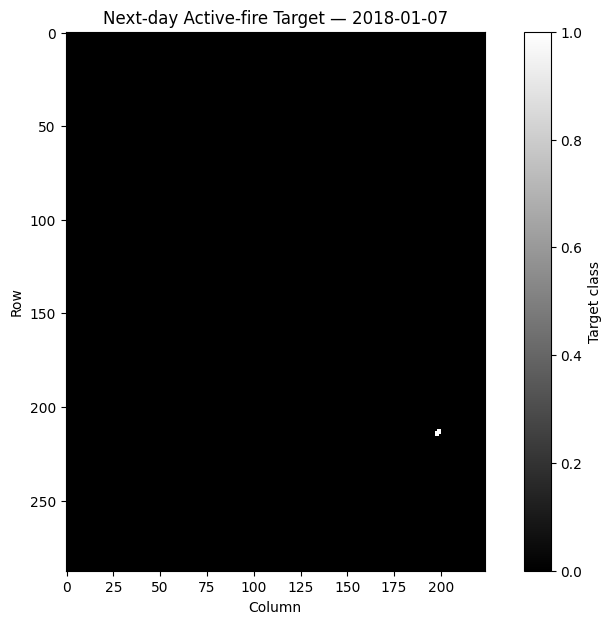

In [36]:
# 12. TARGET SPATIAL VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(target_np, cmap="gray", interpolation="nearest")
plt.title("Next-day Active-fire Target — 2018-01-07")
plt.xlabel("Column")
plt.ylabel("Row")
plt.colorbar(label="Target class")

plt.show()

In [37]:
# Count positive pixels by row and column

fire_rows, fire_cols = np.where(target_np == 1)

print("Fire pixel coordinates (row, column):")

for row, col in zip(fire_rows, fire_cols):
    print((int(row), int(col)))

Fire pixel coordinates (row, column):
(212, 198)
(212, 199)
(213, 197)
(213, 198)
(213, 199)
(214, 197)
(214, 198)
(214, 199)
(215, 197)
(215, 198)


## Spatial Distribution of Next-day Active-fire Target

Event: `fire_21458798`  
Target date: `2018-01-07`

The target visualization shows 10 positive pixels forming
one compact, contiguous cluster.

- Crop dimensions: 288 × 224
- Positive pixel count: 10
- Row coordinates: 212–215
- Column coordinates: 197–199
- Approximate location: lower-right region of the crop

The positive target occupies a very small portion of the
evaluation raster, illustrating the spatial sparsity and
class imbalance of this sample.

In [38]:
from pathlib import Path

PROJECT_ROOT = Path("/content/fireguard")

print("Project directory exists:", PROJECT_ROOT.exists())

print("\nNotebook files:")
for notebook in PROJECT_ROOT.rglob("*.ipynb"):
    print(notebook)


Project directory exists: True

Notebook files:


In [1]:
import sys
import torch
import rasterio
import numpy as np
import pandas as pd

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Rasterio:", rasterio.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: c:\Projects\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
Rasterio: 1.4.4
NumPy: 2.4.6
Pandas: 3.1.1


In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path(r"C:\Projects\fireguard")
WSTS_ROOT = Path(r"C:\Projects\WildfireSpreadTS")

DATA_ROOT = Path(r"G:\My Drive\FireGuard\data\extracted")
MANIFEST_DIR = Path(r"G:\My Drive\FireGuard\data\manifests")
MANIFEST_PATH = MANIFEST_DIR / "wsts_event_metadata.csv"

sys.path.insert(0, str(WSTS_ROOT))

print("FireGuard:", PROJECT_ROOT.exists())
print("WSTS baseline:", WSTS_ROOT.exists())
print("Dataset:", DATA_ROOT.exists())
print("Manifest:", MANIFEST_PATH.exists())

FireGuard: True
WSTS baseline: True
Dataset: True
Manifest: True


In [3]:
from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("WSTS loader imported successfully.")

ImportError: cannot import name 'T_co' from 'torch.utils.data.dataset' (c:\Projects\.venv\Lib\site-packages\torch\utils\data\dataset.py)

In [4]:
from pathlib import Path

loader_path = WSTS_ROOT / "src" / "dataloader" / "FireSpreadDataset.py"

with open(loader_path, "r", encoding="utf-8") as f:
    source = f.read()

print("\n".join(source.splitlines()[:18]))

from pathlib import Path
from typing import List, Optional

import rasterio
from torch.utils.data import Dataset
import torch
import numpy as np
from torch.utils.data.dataset import T_co
import glob
import warnings
from .utils import get_means_stds_missing_values, get_indices_of_degree_features
import torchvision.transforms.functional as TF
import h5py
from datetime import datetime


class FireSpreadDataset(Dataset):
    def __init__(self, data_dir: str, included_fire_years: List[int], n_leading_observations: int,


In [5]:
from pathlib import Path

loader_path = WSTS_ROOT / "src" / "dataloader" / "FireSpreadDataset.py"

with open(loader_path, "r", encoding="utf-8") as f:
    source = f.read()

old_import = "from torch.utils.data.dataset import T_co"
new_import = (
    "from typing import TypeVar\n"
    "T_co = TypeVar('T_co', covariant=True)"
)

if old_import in source:
    source = source.replace(old_import, new_import, 1)

    with open(loader_path, "w", encoding="utf-8") as f:
        f.write(source)

    print("Compatibility patch applied.")
elif new_import in source:
    print("Compatibility patch already applied.")
else:
    raise RuntimeError("Expected T_co import not found. No changes made.")

Compatibility patch applied.


In [6]:
from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("WSTS loader imported successfully.")

WSTS loader imported successfully.


In [7]:
import subprocess

result = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=WSTS_ROOT,
    capture_output=True,
    text=True,
    check=True
)

print("Pinned commit:", result.stdout.strip())

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=WSTS_ROOT,
    capture_output=True,
    text=True,
    check=True
)

print("\nLocal modifications:")
print(status.stdout)

Pinned commit: f62dc49f2c2a6d249c071533ae5340c0d01bfb95

Local modifications:
 M src/dataloader/FireSpreadDataset.py
?? src/__pycache__/
?? src/dataloader/__pycache__/



In [8]:
import shutil

for cache_dir in [
    WSTS_ROOT / "src" / "__pycache__",
    WSTS_ROOT / "src" / "dataloader" / "__pycache__",
]:
    if cache_dir.exists():
        shutil.rmtree(cache_dir)

print("Python cache directories removed.")

Python cache directories removed.


In [9]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=WSTS_ROOT,
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)

 M src/dataloader/FireSpreadDataset.py



In [10]:
from src.dataloader.FireSpreadDataset import FireSpreadDataset

print("WSTS loader imported successfully.")

WSTS loader imported successfully.


In [11]:
import rasterio

event_dir = DATA_ROOT / "2021" / "fire_25017306"
tif_files = sorted(event_dir.glob("*.tif"))

sample_tif = tif_files[0]

with rasterio.open(sample_tif) as src:
    print("File:", sample_tif.name)
    print("Dimensions:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data type:", src.dtypes[0])

    arr = src.read(1)
    print("Band 0 shape:", arr.shape)
    print("NaN percentage:", rasterio.band(src, 1).ds.count)

File: 2021-03-19.tif
Dimensions: 231 x 315
Bands: 23
CRS: EPSG:32610
Resolution: (375.0, 375.0)
Data type: float32
Band 0 shape: (315, 231)
NaN percentage: 23


In [12]:
import numpy as np

print("Band 0 NaN percentage:", np.isnan(arr).mean() * 100)


Band 0 NaN percentage: 0.0


In [13]:
import numpy as np
import pandas as pd
import rasterio

event_dir = DATA_ROOT / "2021" / "fire_25017306"

focus_bands = {
    0: "VIIRS_M11",
    1: "VIIRS_I2",
    2: "VIIRS_I1",
    3: "NDVI",
    4: "EVI2",
    5: "Precipitation",
    12: "Slope",
    14: "Elevation",
    15: "PDSI"
}

daily_results = []

tif_files = sorted(event_dir.glob("*.tif"))

for tif_path in tif_files:
    with rasterio.open(tif_path) as src:

        for band_index, band_name in focus_bands.items():

            arr = src.read(band_index + 1)

            nan_count = np.isnan(arr).sum()
            total_pixels = arr.size

            daily_results.append({
                "date": tif_path.stem,
                "band_index": band_index,
                "band_name": band_name,
                "nan_count": int(nan_count),
                "total_pixels": int(total_pixels),
                "nan_percentage": (
                    nan_count / total_pixels * 100
                )
            })

daily_missingness_df = pd.DataFrame(daily_results)

print("Number of TIFFs:", len(tif_files))
print("Audit records:", len(daily_missingness_df))

display(
    daily_missingness_df.pivot(
        index="date",
        columns="band_index",
        values="nan_percentage"
    ).round(3)
)

Number of TIFFs: 22
Audit records: 198


band_index,0,1,2,3,4,5,12,14,15
date,,,,,,,,,
2021-03-19,0.000,0.000,0.000,100.0,100.0,0.0,0.0,0.0,0.0
2021-03-20,100.000,100.000,100.000,100.0,100.0,0.0,0.0,0.0,0.0
2021-03-21,73.028,73.028,73.028,100.0,100.0,0.0,0.0,0.0,0.0
2021-03-22,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0
2021-03-23,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0
2021-03-24,26.972,26.972,26.972,0.0,0.0,0.0,0.0,0.0,0.0
2021-03-25,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0
2021-03-26,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0
2021-03-27,26.972,26.972,26.972,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
import numpy as np
import pandas as pd
import rasterio

event_dir = DATA_ROOT / "2021" / "fire_25017306"

dates_to_compare = [
    "2021-03-19",
    "2021-03-20",
    "2021-03-21",
    "2021-03-24",
    "2021-03-27",
    "2021-04-03",
    "2021-04-04",
    "2021-04-05",
    "2021-04-07",
    "2021-04-09",
]

bands_to_compare = {
    0: "VIIRS_M11",
    3: "NDVI",
}

def calculate_iou(mask_a, mask_b):
    intersection = np.logical_and(mask_a, mask_b).sum()
    union = np.logical_or(mask_a, mask_b).sum()

    return intersection / union if union else 1.0

temporal_iou_results = []

for band, band_name in bands_to_compare.items():

    masks = {}

    for date in dates_to_compare:
        tif_path = event_dir / f"{date}.tif"

        if not tif_path.exists():
            print("Missing file:", tif_path)
            continue

        with rasterio.open(tif_path) as src:
            masks[date] = np.isnan(src.read(band + 1))

    for i, date_a in enumerate(masks):
        for date_b in list(masks)[i + 1:]:
            iou = calculate_iou(
                masks[date_a],
                masks[date_b]
            )

            temporal_iou_results.append({
                "band": band_name,
                "date_a": date_a,
                "date_b": date_b,
                "IoU": iou
            })

temporal_iou_df = pd.DataFrame(temporal_iou_results)

display(temporal_iou_df.round(6))

,band,date_a,date_b,IoU
0,VIIRS_M11,2021-03-19,2021-03-20,0.0
1,VIIRS_M11,2021-03-19,2021-03-21,0.0
2,VIIRS_M11,2021-03-19,2021-03-24,0.0
3,VIIRS_M11,2021-03-19,2021-03-27,0.0
4,VIIRS_M11,2021-03-19,2021-04-03,0.0
...,...,...,...,...
85,NDVI,2021-04-04,2021-04-07,0.0
86,NDVI,2021-04-04,2021-04-09,0.0
87,NDVI,2021-04-05,2021-04-07,0.0
88,NDVI,2021-04-05,2021-04-09,0.0


In [15]:
temporal_iou_path = (
    MANIFEST_DIR / "wsts_2021_fire_25017306_temporal_iou.csv"
)

temporal_iou_df.to_csv(temporal_iou_path, index=False)

print("Saved:", temporal_iou_path)

Saved: G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_temporal_iou.csv


In [17]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import rasterio

# --------------------------------------------------
# 1. Define paths
# --------------------------------------------------

DATA_ROOT = Path(r"G:\My Drive\FireGuard\data\extracted")
MANIFEST_DIR = Path(r"G:\My Drive\FireGuard\data\manifests")

event_dir = DATA_ROOT / "2021" / "fire_25017306"

# --------------------------------------------------
# 2. Define dates to compare
# --------------------------------------------------

selected_dates = [
    "2021-03-19",
    "2021-03-20",
    "2021-03-21",
    "2021-03-24",
    "2021-03-27",
    "2021-04-03",
    "2021-04-04",
    "2021-04-05",
    "2021-04-07",
    "2021-04-09",
]

# --------------------------------------------------
# 3. Define band names and indices
#    Indices are zero-based for NumPy.
# --------------------------------------------------

bands_to_check = {
    "VIIRS_M11": 0,
    "VIIRS_I2": 1,
    "VIIRS_I1": 2,
    "NDVI": 3,
    "EVI2": 4,
}

# --------------------------------------------------
# 4. Validate paths and input files
# --------------------------------------------------

if not event_dir.exists():
    raise FileNotFoundError(f"Event directory not found: {event_dir}")

missing_files = [
    date for date in selected_dates
    if not (event_dir / f"{date}.tif").exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing TIFF files for dates: {missing_files}"
    )

print("Event directory:", event_dir)
print("Selected dates:", len(selected_dates))
print("Bands:", len(bands_to_check))
print("All selected TIFF files exist.")

# --------------------------------------------------
# 5. Load missing-data masks
#    True = pixel is NaN (missing)
# --------------------------------------------------

missing_masks = {}

for band_name, band_idx in bands_to_check.items():

    missing_masks[band_name] = {}

    for date in selected_dates:

        tif_path = event_dir / f"{date}.tif"

        with rasterio.open(tif_path) as src:
            arr = src.read(band_idx + 1)

        missing_masks[band_name][date] = np.isnan(arr)

# --------------------------------------------------
# 6. Calculate temporal IoU
# --------------------------------------------------

records = []

for band_name in bands_to_check:

    for date_a, date_b in combinations(selected_dates, 2):

        mask_a = missing_masks[band_name][date_a]
        mask_b = missing_masks[band_name][date_b]

        intersection = np.logical_and(mask_a, mask_b).sum()
        union = np.logical_or(mask_a, mask_b).sum()

        # Both masks empty means both dates are complete.
        # IoU is undefined in this case, so record NaN.
        iou = intersection / union if union > 0 else np.nan

        records.append({
            "band": band_name,
            "date_a": date_a,
            "date_b": date_b,
            "missing_pixels_a": int(mask_a.sum()),
            "missing_pixels_b": int(mask_b.sum()),
            "intersection": int(intersection),
            "union": int(union),
            "IoU": iou,
            "both_complete": union == 0,
        })

temporal_iou_diagnostic = pd.DataFrame(records)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("\nTemporal IoU results:")
display(temporal_iou_diagnostic)

print("\nRows per band:")
display(
    temporal_iou_diagnostic.groupby("band").size().to_frame("comparisons")
)

# --------------------------------------------------
# 8. Save results
# --------------------------------------------------

output_path = (
    MANIFEST_DIR / "wsts_2021_fire_25017306_temporal_iou_5bands.csv"
)

temporal_iou_diagnostic.to_csv(output_path, index=False)

print("\nSaved results to:")
print(output_path)

print("\nTotal comparisons:", len(temporal_iou_diagnostic))

Event directory: G:\My Drive\FireGuard\data\extracted\2021\fire_25017306
Selected dates: 10
Bands: 5
All selected TIFF files exist.

Temporal IoU results:


,band,date_a,date_b,missing_pixels_a,missing_pixels_b,intersection,union,IoU,both_complete
0,VIIRS_M11,2021-03-19,2021-03-20,0,72765,0,72765,0.0,False
1,VIIRS_M11,2021-03-19,2021-03-21,0,53139,0,53139,0.0,False
2,VIIRS_M11,2021-03-19,2021-03-24,0,19626,0,19626,0.0,False
3,VIIRS_M11,2021-03-19,2021-03-27,0,19626,0,19626,0.0,False
4,VIIRS_M11,2021-03-19,2021-04-03,0,19626,0,19626,0.0,False
...,...,...,...,...,...,...,...,...,...
220,EVI2,2021-04-04,2021-04-07,0,72765,0,72765,0.0,False
221,EVI2,2021-04-04,2021-04-09,0,72765,0,72765,0.0,False
222,EVI2,2021-04-05,2021-04-07,0,72765,0,72765,0.0,False
223,EVI2,2021-04-05,2021-04-09,0,72765,0,72765,0.0,False



Rows per band:


,comparisons
band,
EVI2,45
NDVI,45
VIIRS_I1,45
VIIRS_I2,45
VIIRS_M11,45



Saved results to:
G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_temporal_iou_5bands.csv

Total comparisons: 225


In [18]:
# Summarize temporal IoU by band

iou_summary = (
    temporal_iou_diagnostic
    .groupby("band")
    .agg(
        comparisons=("IoU", "count"),
        mean_IoU=("IoU", "mean"),
        median_IoU=("IoU", "median"),
        min_IoU=("IoU", "min"),
        max_IoU=("IoU", "max"),
        zero_IoU=("IoU", lambda x: (x == 0).sum()),
        perfect_IoU=("IoU", lambda x: (x == 1).sum()),
        both_complete=("both_complete", "sum"),
    )
    .round(4)
)

display(iou_summary)

,comparisons,mean_IoU,median_IoU,min_IoU,max_IoU,zero_IoU,perfect_IoU,both_complete
band,,,,,,,,
EVI2,35,0.2857,0.0000,0.0,1.0,25,10,10
NDVI,35,0.2857,0.0000,0.0,1.0,25,10,10
VIIRS_I1,44,0.3445,0.2697,0.0,1.0,19,9,1
VIIRS_I2,44,0.3445,0.2697,0.0,1.0,19,9,1
VIIRS_M11,44,0.3445,0.2697,0.0,1.0,19,9,1


In [19]:
persistent_pairs = temporal_iou_diagnostic[
    (temporal_iou_diagnostic["IoU"] == 1.0) &
    (temporal_iou_diagnostic["union"] > 0)
].copy()

display(
    persistent_pairs[
        [
            "band",
            "date_a",
            "date_b",
            "missing_pixels_a",
            "missing_pixels_b",
            "intersection",
            "IoU",
        ]
    ]
)

,band,date_a,date_b,missing_pixels_a,missing_pixels_b,intersection,IoU
13,VIIRS_M11,2021-03-20,2021-04-04,72765,72765,72765,1.0
14,VIIRS_M11,2021-03-20,2021-04-05,72765,72765,72765,1.0
16,VIIRS_M11,2021-03-20,2021-04-09,72765,72765,72765,1.0
24,VIIRS_M11,2021-03-24,2021-03-27,19626,19626,19626,1.0
25,VIIRS_M11,2021-03-24,2021-04-03,19626,19626,19626,1.0
30,VIIRS_M11,2021-03-27,2021-04-03,19626,19626,19626,1.0
39,VIIRS_M11,2021-04-04,2021-04-05,72765,72765,72765,1.0
41,VIIRS_M11,2021-04-04,2021-04-09,72765,72765,72765,1.0
43,VIIRS_M11,2021-04-05,2021-04-09,72765,72765,72765,1.0
58,VIIRS_I2,2021-03-20,2021-04-04,72765,72765,72765,1.0


In [20]:
# Cross-band IoU on selected dates

cross_band_dates = [
    "2021-03-21",
    "2021-03-24",
    "2021-04-07",
    "2021-04-09",
]

cross_band_records = []

for date in cross_band_dates:

    for band_a, band_b in combinations(bands_to_check.keys(), 2):

        mask_a = missing_masks[band_a][date]
        mask_b = missing_masks[band_b][date]

        intersection = np.logical_and(mask_a, mask_b).sum()
        union = np.logical_or(mask_a, mask_b).sum()

        iou = intersection / union if union > 0 else np.nan

        cross_band_records.append({
            "date": date,
            "band_a": band_a,
            "band_b": band_b,
            "missing_a": int(mask_a.sum()),
            "missing_b": int(mask_b.sum()),
            "intersection": int(intersection),
            "union": int(union),
            "IoU": iou,
            "both_complete": union == 0,
        })

cross_band_iou_df = pd.DataFrame(cross_band_records)

display(cross_band_iou_df)

# Save results
cross_band_output = (
    MANIFEST_DIR / "wsts_2021_fire_25017306_cross_band_iou.csv"
)

cross_band_iou_df.to_csv(cross_band_output, index=False)

print("Saved:", cross_band_output)
print("Total comparisons:", len(cross_band_iou_df))

,date,band_a,band_b,missing_a,missing_b,intersection,union,IoU,both_complete
0,2021-03-21,VIIRS_M11,VIIRS_I2,53139,53139,53139,53139,1.000000,False
1,2021-03-21,VIIRS_M11,VIIRS_I1,53139,53139,53139,53139,1.000000,False
2,2021-03-21,VIIRS_M11,NDVI,53139,72765,53139,72765,0.730282,False
3,2021-03-21,VIIRS_M11,EVI2,53139,72765,53139,72765,0.730282,False
4,2021-03-21,VIIRS_I2,VIIRS_I1,53139,53139,53139,53139,1.000000,False
5,2021-03-21,VIIRS_I2,NDVI,53139,72765,53139,72765,0.730282,False
6,2021-03-21,VIIRS_I2,EVI2,53139,72765,53139,72765,0.730282,False
7,2021-03-21,VIIRS_I1,NDVI,53139,72765,53139,72765,0.730282,False
8,2021-03-21,VIIRS_I1,EVI2,53139,72765,53139,72765,0.730282,False
9,2021-03-21,NDVI,EVI2,72765,72765,72765,72765,1.000000,False


Saved: G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_cross_band_iou.csv
Total comparisons: 40


In [21]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(
    persistent_pairs[
        [
            "band",
            "date_a",
            "date_b",
            "missing_pixels_a",
            "missing_pixels_b",
            "intersection",
            "union",
            "IoU",
        ]
    ].to_string(index=False)
)

'     band     date_a     date_b  missing_pixels_a  missing_pixels_b  intersection  union  IoU\nVIIRS_M11 2021-03-20 2021-04-04             72765             72765         72765  72765  1.0\nVIIRS_M11 2021-03-20 2021-04-05             72765             72765         72765  72765  1.0\nVIIRS_M11 2021-03-20 2021-04-09             72765             72765         72765  72765  1.0\nVIIRS_M11 2021-03-24 2021-03-27             19626             19626         19626  19626  1.0\nVIIRS_M11 2021-03-24 2021-04-03             19626             19626         19626  19626  1.0\nVIIRS_M11 2021-03-27 2021-04-03             19626             19626         19626  19626  1.0\nVIIRS_M11 2021-04-04 2021-04-05             72765             72765         72765  72765  1.0\nVIIRS_M11 2021-04-04 2021-04-09             72765             72765         72765  72765  1.0\nVIIRS_M11 2021-04-05 2021-04-09             72765             72765         72765  72765  1.0\n VIIRS_I2 2021-03-20 2021-04-04             72765

In [22]:
# --------------------------------------------------
# Cross-band IoU and directional containment
# --------------------------------------------------

cross_band_dates = [
    "2021-03-21",
    "2021-03-24",
    "2021-04-07",
    "2021-04-09",
]

cross_band_records = []

for date in cross_band_dates:

    for band_a, band_b in combinations(bands_to_check.keys(), 2):

        mask_a = missing_masks[band_a][date]
        mask_b = missing_masks[band_b][date]

        intersection = np.logical_and(mask_a, mask_b).sum()
        union = np.logical_or(mask_a, mask_b).sum()

        count_a = mask_a.sum()
        count_b = mask_b.sum()

        iou = intersection / union if union > 0 else np.nan

        # Directional containment
        containment_a_in_b = (
            intersection / count_a if count_a > 0 else np.nan
        )

        containment_b_in_a = (
            intersection / count_b if count_b > 0 else np.nan
        )

        cross_band_records.append({
            "date": date,
            "band_a": band_a,
            "band_b": band_b,
            "missing_a": int(count_a),
            "missing_b": int(count_b),
            "intersection": int(intersection),
            "union": int(union),
            "IoU": iou,
            "A_missing_contained_in_B": containment_a_in_b,
            "B_missing_contained_in_A": containment_b_in_a,
            "both_complete": union == 0,
        })

cross_band_iou_df = pd.DataFrame(cross_band_records)

display(cross_band_iou_df)

# --------------------------------------------------
# Save results
# --------------------------------------------------

cross_band_output = (
    MANIFEST_DIR /
    "wsts_2021_fire_25017306_cross_band_iou_containment.csv"
)

cross_band_iou_df.to_csv(cross_band_output, index=False)

print("Saved:", cross_band_output)
print("Total comparisons:", len(cross_band_iou_df))

,date,band_a,band_b,missing_a,missing_b,intersection,union,IoU,A_missing_contained_in_B,B_missing_contained_in_A,both_complete
0,2021-03-21,VIIRS_M11,VIIRS_I2,53139,53139,53139,53139,1.000000,1.0,1.000000,False
1,2021-03-21,VIIRS_M11,VIIRS_I1,53139,53139,53139,53139,1.000000,1.0,1.000000,False
2,2021-03-21,VIIRS_M11,NDVI,53139,72765,53139,72765,0.730282,1.0,0.730282,False
3,2021-03-21,VIIRS_M11,EVI2,53139,72765,53139,72765,0.730282,1.0,0.730282,False
4,2021-03-21,VIIRS_I2,VIIRS_I1,53139,53139,53139,53139,1.000000,1.0,1.000000,False
5,2021-03-21,VIIRS_I2,NDVI,53139,72765,53139,72765,0.730282,1.0,0.730282,False
6,2021-03-21,VIIRS_I2,EVI2,53139,72765,53139,72765,0.730282,1.0,0.730282,False
7,2021-03-21,VIIRS_I1,NDVI,53139,72765,53139,72765,0.730282,1.0,0.730282,False
8,2021-03-21,VIIRS_I1,EVI2,53139,72765,53139,72765,0.730282,1.0,0.730282,False
9,2021-03-21,NDVI,EVI2,72765,72765,72765,72765,1.000000,1.0,1.000000,False


Saved: G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_cross_band_iou_containment.csv
Total comparisons: 40


In [23]:

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import rasterio

# ==================================================
# 1. Paths and event configuration
# ==================================================

DATA_ROOT = Path(r"G:\My Drive\FireGuard\data\extracted")
MANIFEST_DIR = Path(r"G:\My Drive\FireGuard\data\manifests")

event_dir = DATA_ROOT / "2021" / "fire_25017306"

if not event_dir.exists():
    raise FileNotFoundError(f"Event directory not found: {event_dir}")

tif_files = sorted(event_dir.glob("*.tif"))

print("Event:", event_dir)
print("Number of TIFF files:", len(tif_files))

if len(tif_files) != 22:
    print("WARNING: Expected 22 TIFF files. Verify the event inventory.")

# ==================================================
# 2. Define band indices
# ==================================================

bands = {
    "VIIRS_M11": 0,
    "VIIRS_I2": 1,
    "VIIRS_I1": 2,
    "NDVI": 3,
    "EVI2": 4,
}

reflectance_bands = [
    "VIIRS_M11",
    "VIIRS_I2",
    "VIIRS_I1",
]

vegetation_bands = [
    "NDVI",
    "EVI2",
]

# ==================================================
# 3. Load missingness masks for every date
# ==================================================

missing_masks = {}
date_missingness = []

for tif_path in tif_files:

    date = tif_path.stem
    missing_masks[date] = {}

    with rasterio.open(tif_path) as src:

        for band_name, band_idx in bands.items():

            arr = src.read(band_idx + 1)
            mask = np.isnan(arr)

            missing_masks[date][band_name] = mask

            date_missingness.append({
                "date": date,
                "band": band_name,
                "missing_pixels": int(mask.sum()),
                "total_pixels": int(mask.size),
                "missing_percentage": float(mask.mean() * 100),
            })

date_missingness_df = pd.DataFrame(date_missingness)

print("\nDaily missingness:")
display(date_missingness_df)

# ==================================================
# 4. Within-group mask identity
# ==================================================

group_records = []

for date in missing_masks:

    for group_name, group_bands in [
        ("Reflectance", reflectance_bands),
        ("Vegetation_indices", vegetation_bands),
    ]:

        reference_band = group_bands[0]
        reference_mask = missing_masks[date][reference_band]

        for other_band in group_bands[1:]:

            other_mask = missing_masks[date][other_band]

            identical = np.array_equal(
                reference_mask,
                other_mask
            )

            intersection = np.logical_and(
                reference_mask,
                other_mask
            ).sum()

            union = np.logical_or(
                reference_mask,
                other_mask
            ).sum()

            iou = intersection / union if union > 0 else np.nan

            group_records.append({
                "date": date,
                "group": group_name,
                "band_a": reference_band,
                "band_b": other_band,
                "mask_identical": identical,
                "missing_a": int(reference_mask.sum()),
                "missing_b": int(other_mask.sum()),
                "intersection": int(intersection),
                "union": int(union),
                "IoU": iou,
            })

within_group_df = pd.DataFrame(group_records)

# ==================================================
# 5. Cross-group containment
# ==================================================

containment_records = []

for date in missing_masks:

    reflectance_mask = missing_masks[date]["VIIRS_M11"]
    vegetation_mask = missing_masks[date]["NDVI"]

    intersection = np.logical_and(
        reflectance_mask,
        vegetation_mask
    ).sum()

    union = np.logical_or(
        reflectance_mask,
        vegetation_mask
    ).sum()

    reflectance_count = reflectance_mask.sum()
    vegetation_count = vegetation_mask.sum()

    iou = intersection / union if union > 0 else np.nan

    reflectance_in_vegetation = (
        intersection / reflectance_count
        if reflectance_count > 0 else np.nan
    )

    vegetation_in_reflectance = (
        intersection / vegetation_count
        if vegetation_count > 0 else np.nan
    )

    containment_records.append({
        "date": date,
        "reflectance_missing": int(reflectance_count),
        "vegetation_missing": int(vegetation_count),
        "intersection": int(intersection),
        "union": int(union),
        "IoU": iou,
        "reflectance_contained_in_vegetation":
            reflectance_in_vegetation,
        "vegetation_contained_in_reflectance":
            vegetation_in_reflectance,
    })

containment_df = pd.DataFrame(containment_records)

# ==================================================
# 6. Event-level summary
# ==================================================

group_summary = (
    within_group_df
    .groupby("group")
    .agg(
        comparisons=("mask_identical", "count"),
        identical_masks=("mask_identical", "sum"),
        non_identical_masks=(
            "mask_identical",
            lambda x: (~x).sum()
        ),
        mean_IoU=("IoU", "mean"),
    )
    .reset_index()
)

print("\nWithin-group mask identity summary:")
display(group_summary)

print("\nDaily reflectance vs vegetation-index containment:")
display(containment_df)

# ==================================================
# 7. Save all outputs
# ==================================================

daily_output = (
    MANIFEST_DIR /
    "wsts_2021_fire_25017306_22day_band_missingness.csv"
)

group_output = (
    MANIFEST_DIR /
    "wsts_2021_fire_25017306_22day_within_group_mask_audit.csv"
)

containment_output = (
    MANIFEST_DIR /
    "wsts_2021_fire_25017306_22day_cross_group_containment.csv"
)

date_missingness_df.to_csv(daily_output, index=False)
within_group_df.to_csv(group_output, index=False)
containment_df.to_csv(containment_output, index=False)

print("\nSaved files:")
print(daily_output)
print(group_output)
print(containment_output)

print("\nAudit complete.")


Event: G:\My Drive\FireGuard\data\extracted\2021\fire_25017306
Number of TIFF files: 22

Daily missingness:


,date,band,missing_pixels,total_pixels,missing_percentage
0,2021-03-19,VIIRS_M11,0,72765,0.0
1,2021-03-19,VIIRS_I2,0,72765,0.0
2,2021-03-19,VIIRS_I1,0,72765,0.0
3,2021-03-19,NDVI,72765,72765,100.0
4,2021-03-19,EVI2,72765,72765,100.0
...,...,...,...,...,...
105,2021-04-09,VIIRS_M11,72765,72765,100.0
106,2021-04-09,VIIRS_I2,72765,72765,100.0
107,2021-04-09,VIIRS_I1,72765,72765,100.0
108,2021-04-09,NDVI,72765,72765,100.0



Within-group mask identity summary:


,group,comparisons,identical_masks,non_identical_masks,mean_IoU
0,Reflectance,44,44,0,1.0
1,Vegetation_indices,22,22,0,1.0



Daily reflectance vs vegetation-index containment:


,date,reflectance_missing,vegetation_missing,intersection,union,IoU,reflectance_contained_in_vegetation,vegetation_contained_in_reflectance
0,2021-03-19,0,72765,0,72765,0.000000,NaN,0.000000
1,2021-03-20,72765,72765,72765,72765,1.000000,1.0,1.000000
2,2021-03-21,53139,72765,53139,72765,0.730282,1.0,0.730282
3,2021-03-22,0,0,0,0,NaN,NaN,NaN
4,2021-03-23,0,0,0,0,NaN,NaN,NaN
5,2021-03-24,19626,0,0,19626,0.000000,0.0,NaN
6,2021-03-25,0,0,0,0,NaN,NaN,NaN
7,2021-03-26,0,0,0,0,NaN,NaN,NaN
8,2021-03-27,19626,0,0,19626,0.000000,0.0,NaN
9,2021-03-28,0,0,0,0,NaN,NaN,NaN



Saved files:
G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_22day_band_missingness.csv
G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_22day_within_group_mask_audit.csv
G:\My Drive\FireGuard\data\manifests\wsts_2021_fire_25017306_22day_cross_group_containment.csv

Audit complete.


### Complete temporal and cross-band missingness audit — 2021/fire_25017306

A complete missingness audit was conducted across all 22 daily TIFF files for event `fire_25017306` (19 March–9 April 2021). Five bands were examined: VIIRS_M11, VIIRS_I2, VIIRS_I1, NDVI and EVI2.

#### Within-group mask identity

The three VIIRS reflectance bands exhibited identical missingness masks on all 22 dates (44 pairwise comparisons). NDVI and EVI2 also exhibited identical missingness masks on all 22 dates (22 comparisons). All within-group comparisons had an IoU of 1.0, with no non-identical masks.

#### Cross-group missingness

The relationship between reflectance and vegetation-index missingness varied over time:

- On 19 March, reflectance bands were complete while NDVI/EVI2 were entirely missing.
- On 20 March and 9 April, all five bands shared completely missing masks.
- On 21 March, all reflectance-missing pixels were contained within the NDVI/EVI2 missing mask. Reflectance had 53,139 missing pixels, compared with 72,765 for NDVI/EVI2, giving a containment ratio of 100% in the reflectance-to-vegetation direction.
- On 24 March, 27 March and 3 April, reflectance bands had 19,626 missing pixels while NDVI/EVI2 were complete.
- On 4–5 April, reflectance bands were entirely missing while NDVI/EVI2 were complete.
- On 7–8 April, reflectance bands were complete while NDVI/EVI2 were entirely missing.

#### Conclusion

The audit establishes identical spatial missingness masks within the reflectance group and within the vegetation-index group across the complete 22-day event. However, cross-group relationships vary over time, including product-specific missingness, nested missingness and dates when all five bands share identical missing masks.

These results demonstrate structured, temporally variable and product-dependent missingness. They do not establish the underlying cause of missingness. Original raster values were preserved, and no imputation or mask consolidation was performed.